In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import to_rgba
from sklearn.preprocessing import StandardScaler

import sys
import os
sys.path.insert(0, os.path.abspath("../.."))

from picpy.calibration import BinomialCalibrator, GaussianCalibrator
from picpy import LinearRegression, LogisticRegression
from picpy.penalties import L1Penalty, SCADPenalty, MCPPenalty
from picpy.selection import StabilitySelection, RecursiveSelection

In [8]:

def _offset(k, b):
    return (b**k - 1) // (b - 1)

def plot_tree(level, depth=3, b=2, sel=None, ax=None, labels=True, title=None):
    """
    level : vecteur renvoyé par simulate_tree
    sel   : None                -> arbre seul
            array (p,) d'entiers -> boucle où chaque variable est sélectionnée (0 = jamais)
            array (p, K)        -> fréquences de sélection par boucle (sur R réplications)
    """
    level = np.asarray(level)
    p = len(level)
    n_tree = _offset(depth + 1, b)
    n_dec = int((level == -1).sum()) - 1          # nb de feuilles du leurre

    # positions et arêtes
    pos, edges = {}, []
    for k in range(depth + 1):
        m = b**k
        for j in range(m):
            pos[_offset(k, b) + j] = ((j + 0.5) / m, -k)
            if k < depth:
                edges += [(_offset(k, b) + j, _offset(k + 1, b) + b*j + c) for c in range(b)]
    if n_dec > 0:
        r = n_tree
        pos[r] = (1.35, 0)
        for i in range(n_dec):
            pos[r + 1 + i] = (1.15 + 0.4 * (i + 0.5) / n_dec, -depth)
            edges.append((r, r + 1 + i))

    # boucle et intensité pour chaque variable
    if sel is None:
        it, a = np.zeros(p, int), np.ones(p)
    else:
        sel = np.asarray(sel)
        if sel.ndim == 1:
            it, a = sel.astype(int), np.ones(p)
        else:
            it, a = sel.argmax(1) + 1, sel.max(1)
            it[a == 0] = 0
            a = 0.25 + 0.75 * a
    cmap = plt.get_cmap("tab10")
    col = lambda i: to_rgba("lightgray") if it[i] == 0 else to_rgba(cmap((it[i] - 1) % 10), a[i])

    if ax is None:
        _, ax = plt.subplots(figsize=(11, 1.6 * (depth + 1) + 1))
    for u, v in edges:
        (x1, y1), (x2, y2) = pos[u], pos[v]
        ax.plot([x1, x2], [y1, y2], color="gray", lw=0.7, zorder=1)
    for i, (x, y) in pos.items():
        ax.scatter(x, y, s=650 if b**depth <= 16 else 250,
                   color=col(i), edgecolors="black", linewidths=0.6, zorder=2)
        if labels:
            ax.text(x, y, f"X{i+1}", ha="center", va="center", fontsize=8, zorder=3)

    # séparation arbre / leurre, et bruit sélectionné
    if n_dec > 0:
        ax.axvline(1.075, ls="--", color="gray", lw=0.6)
        ax.text(1.35, 0.55, "Leurre (absent de Y)", ha="center", fontsize=9)
    ax.text(0.5, 0.55, "Arbre de Y", ha="center", fontsize=9)
    noise = level == -2
    if sel is not None and noise.any():
        ax.text(0.5, -depth - 0.7,
                f"Bruit pur sélectionné : {(it[noise] > 0).sum()} / {noise.sum()}",
                ha="center", fontsize=9)

    used = sorted(set(it[it > 0]))
    handles = [Patch(color=cmap((t - 1) % 10), label=f"Boucle {t}") for t in used]
    handles.append(Patch(color="lightgray", label="Non sélectionné"))
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.0, 1), frameon=False)
    ax.set_yticks([-k for k in range(depth + 1)], [f"Niveau {k}" for k in range(depth + 1)])
    ax.set_xticks([])
    ax.set_xlim(-0.05, 1.6 if n_dec > 0 else 1.05)
    ax.set_ylim(-depth - 1, 0.9)
    for s in ["top", "right", "bottom"]:
        ax.spines[s].set_visible(False)
    if title:
        ax.set_title(title)
    plt.tight_layout()
    return ax


def plot_level_heatmap(level, freq, depth=3, ax=None):
    """freq : (p, K) fréquences de sélection par boucle -> moyenne par niveau vrai."""
    level, freq = np.asarray(level), np.asarray(freq)
    rows = list(range(depth + 1)) + [-1, -2]
    names = [f"Niveau {k}" for k in range(depth + 1)] + ["Leurre", "Bruit"]
    M = np.array([freq[level == r].mean(0) for r in rows])
    if ax is None:
        _, ax = plt.subplots(figsize=(1.2 * freq.shape[1] + 3, 4))
    im = ax.imshow(M, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center",
                    color="white" if M[i, j] > 0.6 else "black", fontsize=8)
    ax.set_xticks(range(freq.shape[1]), [f"Boucle {t+1}" for t in range(freq.shape[1])])
    ax.set_yticks(range(len(rows)), names)
    plt.colorbar(im, ax=ax, label="Fréquence de sélection moyenne")
    plt.tight_layout()
    return ax

In [9]:
def simulate_tree(n=500, depth=3, b=2, sigma=0.3, beta=1.0,
                  n_decoy_leaves=8, p_noise=50, seed=0):
    rng = np.random.default_rng(seed)
    L = b**depth
    leaves = rng.standard_normal((n, L))
    cols, level = [], []
    for k in range(depth + 1):                 # k=0 racine, k=depth feuilles
        size = b**(depth - k)
        for j in range(b**k):
            s = leaves[:, j*size:(j+1)*size].sum(1)
            cols.append(s + sigma*np.sqrt(size)*rng.standard_normal(n))
            level.append(k)
    # sous-arbre leurre : même structure, absent de Y
    dl = rng.standard_normal((n, n_decoy_leaves))
    cols += [dl.sum(1), *dl.T]
    level += [-1]*(1 + n_decoy_leaves)
    cols += list(rng.standard_normal((p_noise, n)))
    level += [-2]*p_noise
    X = np.column_stack(cols)
    X = (X - X.mean(0)) / X.std(0)
    Z = leaves.sum(1) / np.sqrt(L)
    y = beta*Z + rng.standard_normal(n)
    return X, y, np.array(level)

In [10]:
depth, b = 3, 2
X, y, level = simulate_tree(depth=depth, b=b, sigma=0.3)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("X mean:", X_scaled.mean(axis=0).max())
print("X variance:", X_scaled.var(axis=0).mean())

X mean: 8.471001677889945e-17
X variance: 1.0


In [11]:
recursive = RecursiveSelection(
    model=LinearRegression(lambda_=0, penalty=SCADPenalty(), refit=False),
    calibrator=GaussianCalibrator(alpha=0.05, n_simu=2000),
    max_iter=100,
    progress=True,
)
recursive.fit(X_scaled, y)

print("Selected variables:", recursive.supports_)

Recursive Selection:   0%|          | 0/100 [00:00<?, ?it/s]

Selected variables: [array([0]), array([1, 2]), array([3, 4, 5, 6]), array([ 7,  8,  9, 10, 11, 12, 13, 14])]


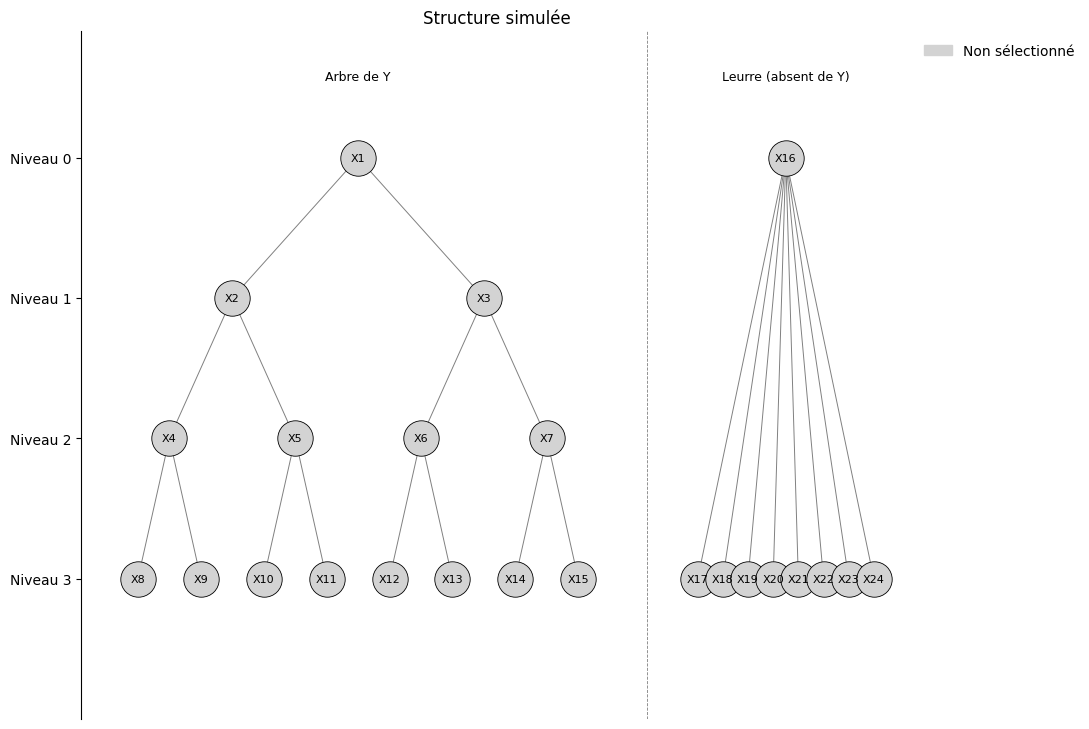

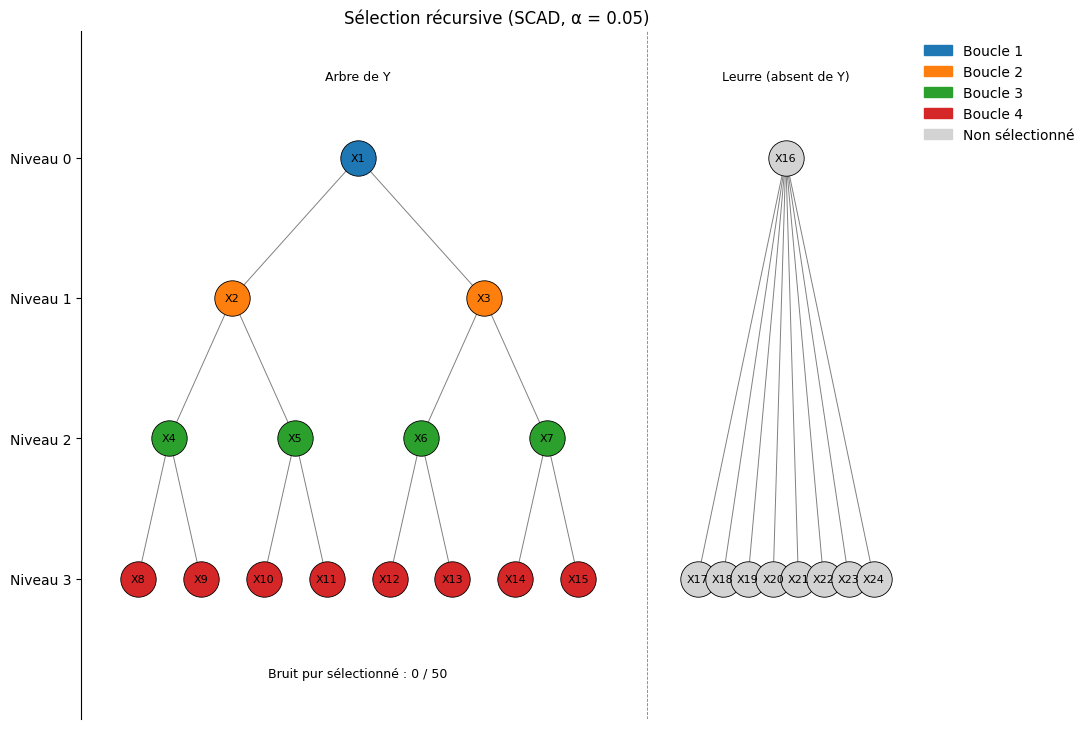

In [12]:
plot_tree(level, depth, b, title="Structure simulée")


def supports_to_iters(supports, p):
    iters = np.zeros(p, dtype=int)
    for t, S in enumerate(supports, start=1):
        iters[np.asarray(S, dtype=int)] = t
    return iters

iters = supports_to_iters(recursive.supports_, X_scaled.shape[1])
plot_tree(level, depth, b, sel=iters, title="Sélection récursive (SCAD, α = 0.05)")
plt.show()